# gas_trend 01 — What the model sees and what it must predict
**Question.** The box's gas chain raises its alarm when the smoke is already clear. Can the gateway, looking at the *last 12 scan results*, warn **earlier**, i.e. say "smoke onset within the next 8 scans" before the chain's own threshold is crossed?

**Data.** Real BME688/690 recordings (Mendeley Data "Dataset Smoke Detection", CC BY 4.0): 5 nodes, 20 files, 38 episodes (2 sensors per file), 13 097 scans. Node 1 is the 2021 burn; nodes 2–5 the 2025 burn. Phases are numbered by order (the authors' tags are undocumented): 0 = clean start, 1 = no response, ≥ 2 = the first response… Honest limitation: indoor-style burns, not forest fuel.

In [1]:
import sys, pathlib
import numpy as np
import matplotlib.pyplot as plt
ROOT = pathlib.Path.cwd().resolve().parents[1]
sys.path[:0] = [str(ROOT / "python/src"), str(ROOT.parent / "common/python/src"), str(ROOT.parents[1] / "box/gas_chain/python/src")]
from gas_chain import data_mendeley as D
from gas_trend import chain_features, build_samples, experiments as E
from gas_trend.data import onset_alarm_times
data = D.load_all()
print("scans:", len(data["episode"]), "| episodes:", len(np.unique(data["episode"])), "| nodes:", np.unique(data["node"]))
print("median seconds between scans per node:", {int(n): float(np.median(data["dt"][data["node"] == n])) for n in np.unique(data["node"])})

scans: 13097 | episodes: 38 | nodes: [1 2 3 4 5]
median seconds between scans per node: {1: 27.0, 2: 25.0, 3: 11.0, 4: 19.0, 5: 37.0}


Scan period differs a lot between files (11 s to 111 s). "8 scans ahead" is therefore between 1.5 and 15 minutes depending on the file: we report lead times in **seconds**.

## 1. Replay through the box chain
Each episode is replayed through the real `GasChain` (quality → filter → T/RH compensation → baseline → bands → score + class). For each scan the gateway receives 7 numbers: `score, depth, band1..3, temp, rh`.

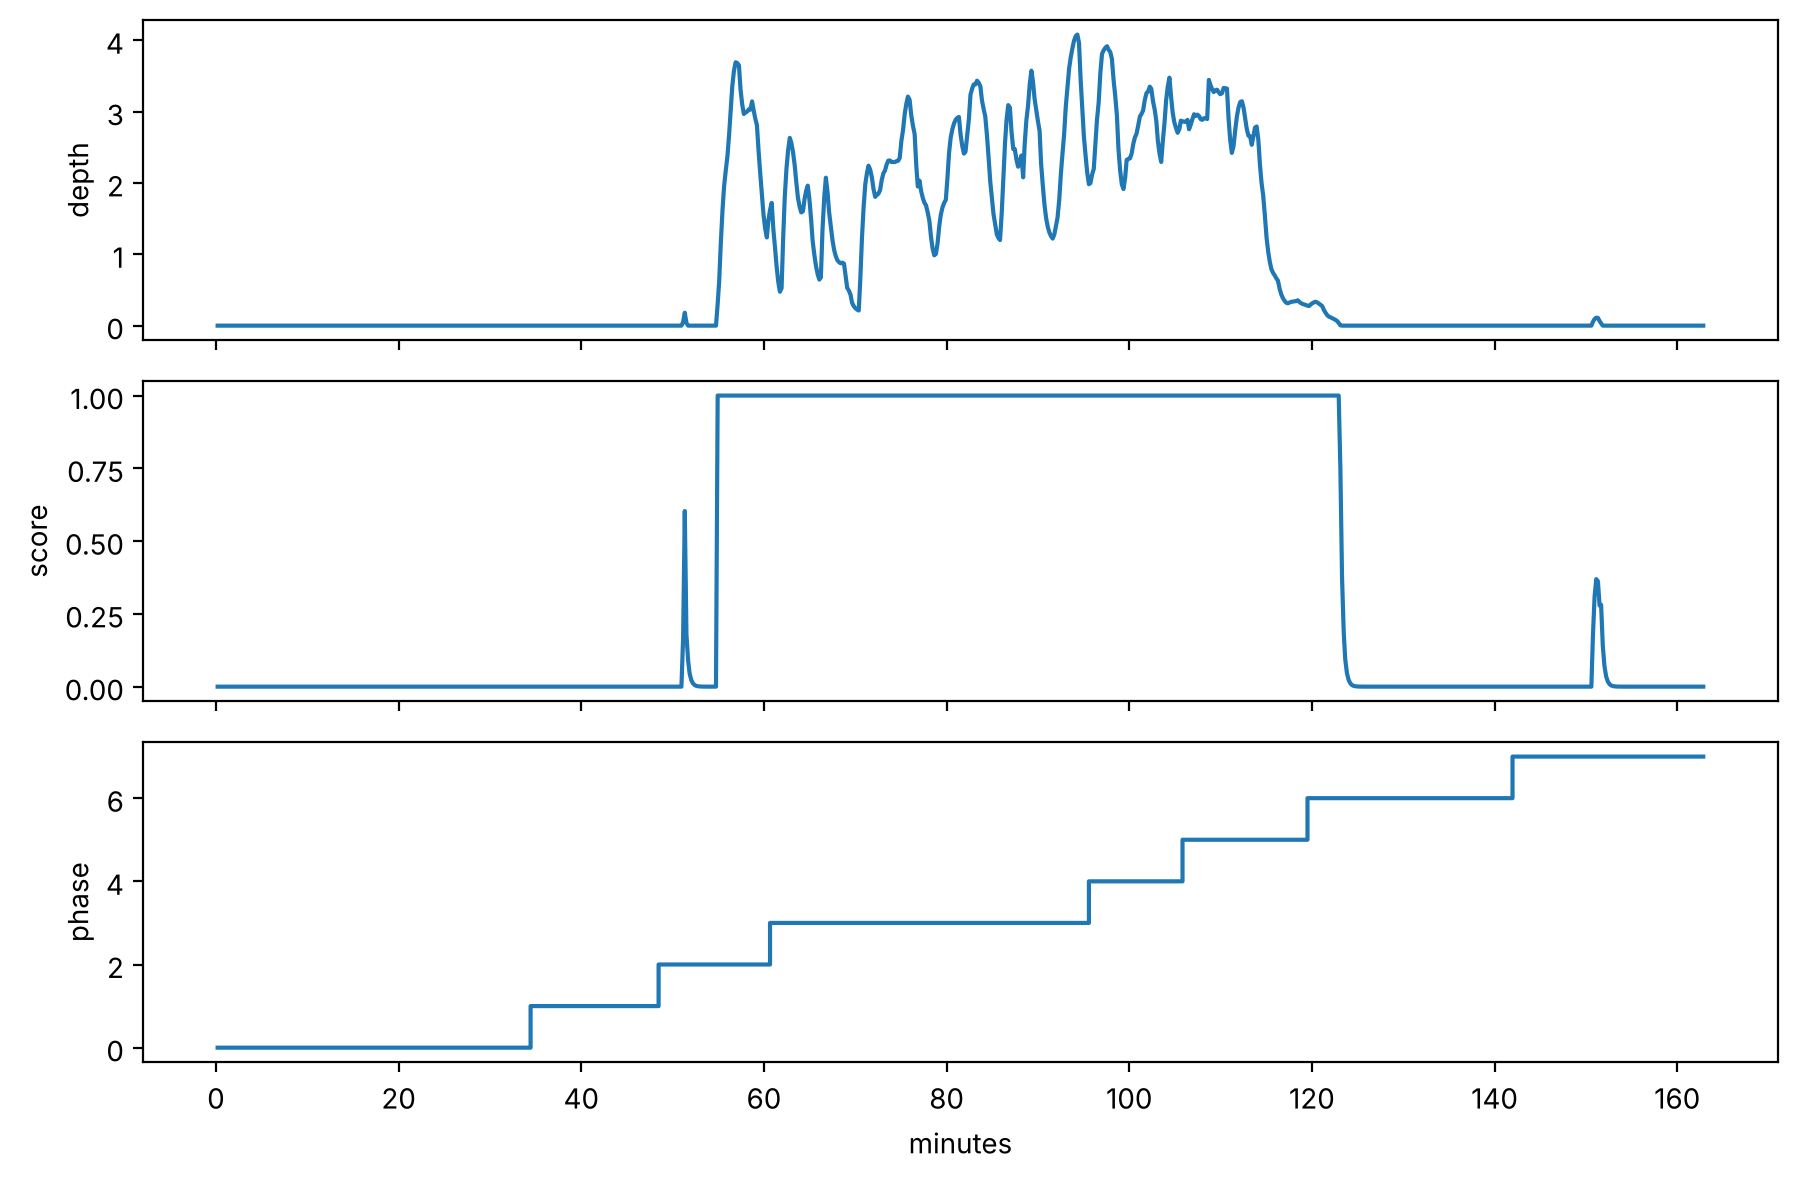

In [2]:
f = chain_features(data)
ep = 22                                              # node 3, a long recording
m = f["episode"] == ep
fig, ax = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
ax[0].plot(f["t"][m] / 60, f["X"][m, 1]); ax[0].set_ylabel("depth")
ax[1].plot(f["t"][m] / 60, f["X"][m, 0]); ax[1].set_ylabel("score")
ax[2].plot(f["t"][m] / 60, f["phase"][m], drawstyle="steps"); ax[2].set_ylabel("phase"); ax[2].set_xlabel("minutes")
plt.tight_layout(); plt.show()

## 2. The target
Onset = first scan of phase 2. A window ending at scan *k* (after the chain's warm-up, at least 12 scans in) gets **label 1 if the onset is within the next 8 scans, else 0**. Scans at or after the onset are excluded — from there on, the chain does the job.
This is very imbalanced and the positives are few: about 8 per episode.

In [3]:
X, meta = build_samples(f)
print("windows:", X.shape, "| positives:", int(meta["y"].sum()), f"({100*meta['y'].mean():.1f} %)")
al = onset_alarm_times(f)
lag = [a["t_alarm"] - a["t_onset"] for a in al.values() if not np.isnan(a["t_alarm"])]
print("episodes with a chain alarm:", len(lag), "of", len(al), "| chain alarm comes %.0f s (median) after the onset" % np.median(lag))

windows: (3102, 12, 7) | positives: 304 (9.8 %)
episodes with a chain alarm: 38 of 38 | chain alarm comes 189 s (median) after the onset


## 3. The question the data can answer
The best case for an early warning is when the chain itself is slow: **median 0–200 s between onset and chain alarm** is the room we have. We need a flag in the 8 scans before the onset *and* below the chain's false-alarm rate.

## 4. How we avoid fooling ourselves
- **Leave-one-node-out**: the test node is never in training or validation (unit test). The next node (cyclic) is the validation node.
- **Equal false-alarm budget**: each model's threshold is chosen on the validation node so that its flags on clean air (phase 0) do not exceed the chain's false-smoke rate there; the test node then shows whether that holds.
- **Distance proxy**: `dilute` scales the fire's effect on ln R by 1.0, 0.5, 0.25 (noise kept). A stand-in only: real dilution is nonlinear and other gases appear.